# 03 Napoved za jutri: dnevni PM2.5 na Bežigradu iz vremena

**Namen:** pokazati, kako iz vremenske napovedi in današnjih meritev narediti preprosto napoved jutrišnjega onesnaženja in jo pošteno oceniti. **Ciljna skupina:** občani (opozorilo za jutri) in odločevalci (zgodnje opozarjanje).

**Vhodi:** dnevni PM2.5 Bežigrad (**meritev**: EEA validirano dnevno 2018–2020, ARSO urno → dnevno 2021–2026), ERA5 za točko Bežigrad (**model**, reanaliza), CAMS (**model**, ~10 km), CAMx ARSO (**model**, 4,4 km: napoved za jutri iz ur +25 … +48 kot značilka in za primerjavo, 2023–2025; napoved za isti dan samo za primerjavo), koledar.

**Pošteno opozorilo:** model se uči na ERA5, ki je *analiza* vremena za nazaj, ne napoved. Pri uporabi z resnično napovedjo (zadnja celica) se napaki modela doda še napaka vremenske napovedi; uspešnost spodaj je torej zgornja meja. Test je strogo ločen: učenje do 31. 10. 2025, ocena na zimi 2025/26.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys; sys.path.insert(0, ".")
from paket import *
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
plt.rcParams["figure.dpi"] = 100; pd.set_option("display.width", 160)

# cilj: dnevni PM2.5 Bežigrad (meritev)
eea = pd.read_csv(P/"01_meritve/eea_si_validirano_dnevno_2013_2025.csv", parse_dates=["time_utc"])
eea = eea[(eea.station_code == "SI0003A") & (eea.pollutant == "PM2.5")].set_index("time_utc").value.rename("pm25")
arso = dnevno(nalozi_arso(["E403"]).drop(columns="station_code")).set_index("dan").pm25
y = pd.concat([eea[eea.index < "2021-01-11"], arso[arso.index >= "2021-01-11"]]).sort_index()
y.index = y.index.tz_localize(None) if y.index.tz is None else y.index.tz_convert(None)
y = y[~y.index.duplicated()]
print(f"dnevni PM2.5 Bežigrad: {y.notna().sum()} dni, {y.index.min():%Y-%m-%d} – {y.index.max():%Y-%m-%d}; EEA gravimetrija do 10. 1. 2021, nato ARSO urno")

dnevni PM2.5 Bežigrad: 3205 dni, 2018-01-01 – 2026-11-20; EEA gravimetrija do 10. 1. 2021, nato ARSO urno


## 1. Učna tabela

Za vsak dan *d* napovedujemo PM2.5 za dan *d+1*. Spremenljivke: vreme dneva *d+1* iz ERA5 (kot nadomestek napovedi: povprečen in največji veter, povprečna in najmanjša višina mejne plasti, temperatura, padavine, vlaga, sevanje, oblačnost), CAMS za *d+1*, današnji in včerajšnji PM2.5 (**vztrajnost**), dan v tednu in mesec.

In [2]:
era = nalozi_era5("E403")
E = era.set_index("time_utc").tz_convert(None)
F = pd.DataFrame({
    "veter_povp": E.wind_speed_10m.resample("D").mean(), "veter_max": E.wind_speed_10m.resample("D").max(),
    "blh_povp": E.boundary_layer_height.resample("D").mean(), "blh_min": E.boundary_layer_height.resample("D").min(),
    "blh_vecer": E.boundary_layer_height.between_time("17:00", "23:00").resample("D").mean(),
    "temp_povp": E.temperature_2m.resample("D").mean(), "temp_min": E.temperature_2m.resample("D").min(),
    "padavine": E.precipitation.resample("D").sum(min_count=18), "vlaga": E.relative_humidity_2m.resample("D").mean(),
    "sevanje_max": E.shortwave_radiation.resample("D").max(), "oblacnost": E.cloud_cover.resample("D").mean(),
})
cams = nalozi_cams("E403").set_index("time_utc").tz_convert(None).cams_pm25.resample("D").mean().rename("cams_pm25")
camx = nalozi_camx("E403").set_index("time_utc").tz_convert(None).camx_pm25.resample("D").mean().rename("camx_pm25")  # ure +1 … +24
camx_j = nalozi_camx_jutri("E403").set_index("time_utc").tz_convert(None).camx_pm25.resample("D").mean().rename("camx_pm25_jutri")  # ure +25 … +48, po ciljnem dnevu
X = F.shift(-1).add_suffix("_jutri")                       # vreme za jutri (ERA5 kot nadomestek napovedi)
X["cams_jutri"] = cams.shift(-1)
X["camx_jutri"] = camx_j.shift(-1).reindex(X.index)        # napoved CAMx za jutri, izdana danes zjutraj (2023–2025; prej NaN, kar gradient boosting zna)
X["pm25_danes"] = y.reindex(X.index)
X["pm25_vceraj"] = X.pm25_danes.shift(1)
X["dan_v_tednu_jutri"] = (X.index + pd.Timedelta(days=1)).dayofweek
X["mesec_jutri"] = (X.index + pd.Timedelta(days=1)).month
X["cilj"] = y.reindex(X.index).shift(-1)                   # PM2.5 jutri
X = X.dropna(subset=["cilj", "pm25_danes"]).loc["2018-01-01":]
znacilke = [c for c in X.columns if c != "cilj"]
# CAMx za dan d+1 je napoved za isti dan, na voljo šele zjutraj dne d+1 -> NI značilka (ob napovedi večer prej je še ni), samo primerjava
X["camx_danes"] = camx.shift(-1).reindex(X.index)

uc = X.loc[: "2025-10-31"]; test = X.loc["2025-11-01": "2026-03-31"]
print(f"učenje: {len(uc)} dni (2018 – okt 2025), test zima 2025/26: {len(test)} dni")
X.tail(3).round(1)

učenje: 2808 dni (2018 – okt 2025), test zima 2025/26: 151 dni


,veter_povp_jutri,veter_max_jutri,blh_povp_jutri,blh_min_jutri,blh_vecer_jutri,temp_povp_jutri,temp_min_jutri,padavine_jutri,vlaga_jutri,sevanje_max_jutri,oblacnost_jutri,cams_jutri,camx_jutri,pm25_danes,pm25_vceraj,dan_v_tednu_jutri,mesec_jutri,cilj,camx_danes
time_utc,,,,,,,,,,,,,,,,,,,
2026-11-09,2.8,4.1,69.0,20.0,33.6,9.0,6.8,7.8,97.8,151.0,96.8,29.0,NaN,26.0,20.9,1,11,19.9,14.5
2026-11-10,2.2,4.8,105.6,15.0,18.6,9.4,8.7,6.2,95.7,105.0,99.7,37.5,NaN,19.9,26.0,2,11,10.7,15.8
2026-11-11,2.2,4.4,44.4,10.0,27.9,10.8,9.0,55.1,97.7,160.0,100.0,21.8,NaN,10.7,19.9,3,11,10.9,11.5


## 2. Trije pristopi in poštena primerjava

- **Vztrajnost:** jutri = danes (najpreprostejša napoved, ki jo mora vsak model premagati).
- **CAMS:** jutrišnja vrednost modela CAMS kot napoved (regionalni model, **brez** lokalnega umerjanja).
- **CAMx ARSO za jutri** (`camx_jutri`): dnevno povprečje ur +25 … +48 iz zagona ob 00 UTC dne *d*, torej prava napoved za *d+1*, znana zjutraj dne *d*; je tudi **značilka modela** (na voljo 2023–2025, prej in v 2026 NaN, kar gradient boosting prenese). **CAMx za isti dan** (`camx`, samo za primerjavo): ure +1 … +24 iz zagona dne *d+1*, znana šele zjutraj dne *d+1*, zato ni značilka. V testni zimi 2025/26 je CAMx za jutri le do 31. 12. 2025 (61 dni).
- **Gradient boosting** (scikit-learn `HistGradientBoostingRegressor`) na vremenu za jutri + vztrajnost + koledar.

Mere na zimi 2025/26: MAE in R², ter matrika zamenjav za *slab dan* (dnevni PM2.5 > 25 µg/m³; WHO smernica je 15, EU letna meja od 2030 je 10).

In [3]:
gb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_depth=4, min_samples_leaf=20, random_state=0)
gb.fit(uc[znacilke], uc.cilj)
nap = pd.DataFrame({"meritev": test.cilj, "vztrajnost": test.pm25_danes, "cams": test.cams_jutri, "camx_jutri": test.camx_jutri, "camx": test.camx_danes, "model": gb.predict(test[znacilke])}, index=test.index)

def mere(p, r, prag=25):
    ok = p.notna() & r.notna(); p, r = p[ok], r[ok]
    mae = (p - r).abs().mean(); r2 = 1 - ((p - r) ** 2).sum() / ((r - r.mean()) ** 2).sum()
    tp = ((p > prag) & (r > prag)).sum(); fp = ((p > prag) & (r <= prag)).sum(); fn = ((p <= prag) & (r > prag)).sum()
    return dict(n=len(r), MAE=round(mae, 1), R2=round(r2, 2), slabih_dni=int((r > prag).sum()), zadetki=int(tp), lazni=int(fp), zgreseni=int(fn),
                obcutljivost=round(tp / (tp + fn), 2) if tp + fn else np.nan, natancnost=round(tp / (tp + fp), 2) if tp + fp else np.nan)
rez = pd.DataFrame({k: mere(nap[k], nap.meritev) for k in ["vztrajnost", "cams", "camx_jutri", "camx", "model"]}).T
print("camx_jutri = napoved CAMx ARSO za jutri (ure +25 … +48, znana zjutraj; v testu do 31. 12. 2025), tudi značilka modela")
print("camx = jutranja napoved CAMx za isti dan (ni na voljo večer prej), samo primerjava")
rez

camx_jutri = napoved CAMx ARSO za jutri (ure +25 … +48, znana zjutraj; v testu do 31. 12. 2025), tudi značilka modela
camx = jutranja napoved CAMx za isti dan (ni na voljo večer prej), samo primerjava


,n,MAE,R2,slabih_dni,zadetki,lazni,zgreseni,obcutljivost,natancnost
vztrajnost,151.0,6.0,0.46,33.0,19.0,14.0,14.0,0.58,0.58
cams,151.0,16.7,-2.16,33.0,32.0,85.0,1.0,0.97,0.27
camx_jutri,61.0,25.0,-6.60,16.0,16.0,31.0,0.0,1.00,0.34
camx,151.0,16.7,-2.54,33.0,31.0,66.0,2.0,0.94,0.32
model,151.0,6.7,0.40,33.0,30.0,29.0,3.0,0.91,0.51


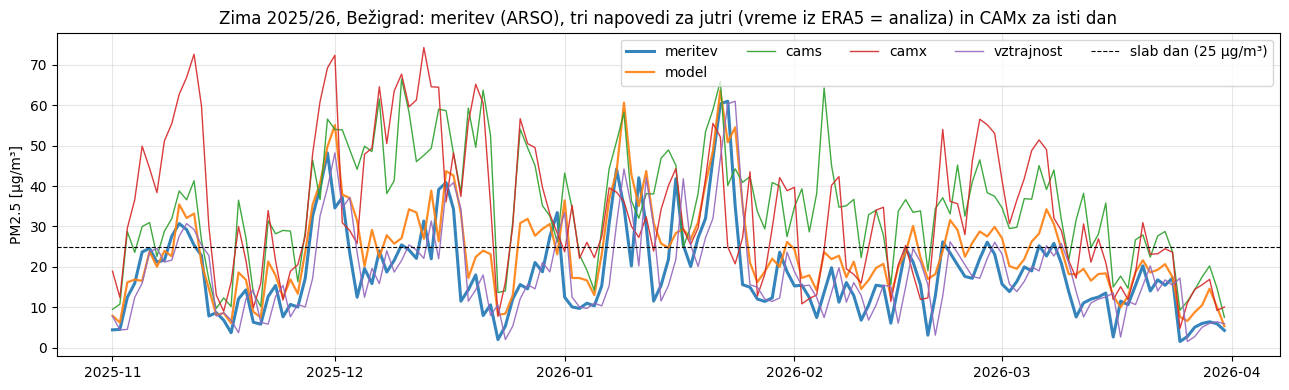

Matrika zamenjav, model (vrstice: napoved slab dan da/ne; stolpci: izmerjen slab dan da/ne):
meritev > 25  False  True 
napoved > 25              
False            89      3
True             29     30


In [4]:
fig, ax = plt.subplots(figsize=(13, 4))
for k, lw in [("meritev", 2.2), ("model", 1.6), ("cams", 1), ("camx", 1), ("vztrajnost", 1)]:
    ax.plot(nap.index, nap[k], lw=lw, alpha=.9, label=k)
ax.axhline(25, color="k", ls="--", lw=.8, label="slab dan (25 µg/m³)")
ax.set(ylabel="PM2.5 [µg/m³]", title="Zima 2025/26, Bežigrad: meritev (ARSO), tri napovedi za jutri (vreme iz ERA5 = analiza) in CAMx za isti dan")
ax.legend(ncol=5); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
print("Matrika zamenjav, model (vrstice: napoved slab dan da/ne; stolpci: izmerjen slab dan da/ne):")
print(pd.crosstab(nap.model > 25, nap.meritev > 25, rownames=["napoved > 25"], colnames=["meritev > 25"]))

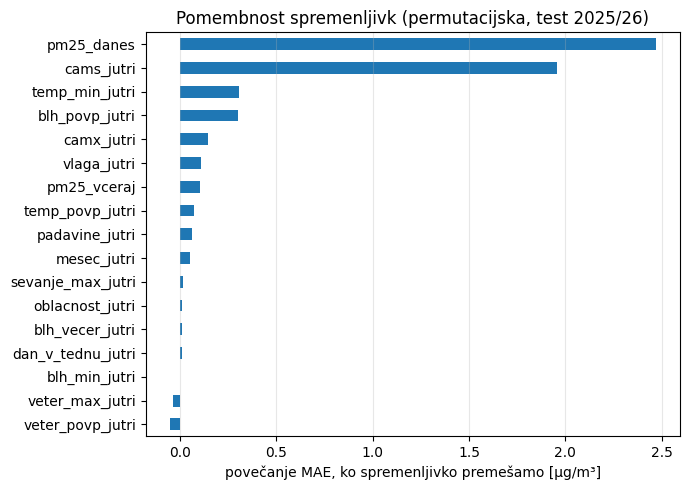

In [5]:
imp = permutation_importance(gb, test[znacilke], test.cilj, n_repeats=10, random_state=0, scoring="neg_mean_absolute_error")
pi = pd.Series(imp.importances_mean, index=znacilke).sort_values()
ax = pi.plot.barh(figsize=(7, 5)); ax.set(xlabel="povečanje MAE, ko spremenljivko premešamo [µg/m³]", title="Pomembnost spremenljivk (permutacijska, test 2025/26)")
ax.grid(alpha=.3, axis="x"); plt.tight_layout(); plt.show()

## 3. Kaj model pove o fiziki

Vztrajnost je močna, ker so epizode večdnevne; vreme za jutri doda informacijo predvsem ob *prehodih* (začetek in konec epizode), kjer vztrajnost zgreši. Model, ki zna zaznati prehod, je za opozarjanje najdragocenejši; spodaj pogledamo napake ravno ob prehodih.

In [6]:
preh = nap[(nap.meritev > 25) != (nap.meritev.shift(1) > 25)].dropna()
print(f"dni s prehodom čez 25 µg/m³ v testu: {len(preh)}")
ost = nap.drop(preh.index)
print("MAE ob prehodih: vztrajnost", round((preh.vztrajnost - preh.meritev).abs().mean(), 1),
      "| CAMS", round((preh.cams - preh.meritev).abs().mean(), 1), "| model", round((preh.model - preh.meritev).abs().mean(), 1),
      "| CAMx jutri", round((preh.camx_jutri - preh.meritev).abs().mean(), 1), "| CAMx isti dan", round((preh.camx - preh.meritev).abs().mean(), 1))
print("MAE na ostalih dneh:  vztrajnost", round((ost.vztrajnost - ost.meritev).abs().mean(), 1),
      "| CAMS", round((ost.cams - ost.meritev).abs().mean(), 1), "| model", round((ost.model - ost.meritev).abs().mean(), 1),
      "| CAMx jutri", round((ost.camx_jutri - ost.meritev).abs().mean(), 1), "| CAMx isti dan", round((ost.camx - ost.meritev).abs().mean(), 1))

dni s prehodom čez 25 µg/m³ v testu: 11
MAE ob prehodih: vztrajnost 10.0 | CAMS 19.9 | model 8.5 | CAMx jutri 32.2 | CAMx isti dan 27.8
MAE na ostalih dneh:  vztrajnost 5.7 | CAMS 16.4 | model 6.5 | CAMx jutri 23.4 | CAMx isti dan 15.8


## 4. Isti model na resnični napovedi (potrebuje internet)

Celica pokliče Open-Meteo (napoved vremena za 3 dni in CAMS), agregira na dnevne spremenljivke enako kot zgoraj, vzame zadnjo dnevno meritev iz paketa (`01_meritve/arso_lj_pm_urno_2026_11_dopolnitev.csv`) in izpiše napoved PM2.5 za jutri in pojutrišnjem. Če interneta ni, celica le izpiše sporočilo.

In [7]:
try:
    import requests
    lat, lon = POSTAJE["E403"]["lat"], POSTAJE["E403"]["lon"]
    w = requests.get("https://api.open-meteo.com/v1/forecast", params={"latitude": lat, "longitude": lon, "timezone": "UTC", "forecast_days": 4,
        "hourly": "temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,cloud_cover,shortwave_radiation,boundary_layer_height"}, timeout=30).json()["hourly"]
    a = requests.get("https://air-quality-api.open-meteo.com/v1/air-quality", params={"latitude": lat, "longitude": lon, "timezone": "UTC", "forecast_days": 4,
        "domains": "cams_europe", "hourly": "pm2_5"}, timeout=30).json()["hourly"]
    H = pd.DataFrame(w).merge(pd.DataFrame(a), on="time"); H["time"] = pd.to_datetime(H.time); H = H.set_index("time")
    Fz = pd.DataFrame({"veter_povp": H.wind_speed_10m.resample("D").mean(), "veter_max": H.wind_speed_10m.resample("D").max(),
        "blh_povp": H.boundary_layer_height.resample("D").mean(), "blh_min": H.boundary_layer_height.resample("D").min(),
        "blh_vecer": H.boundary_layer_height.between_time("17:00", "23:00").resample("D").mean(),
        "temp_povp": H.temperature_2m.resample("D").mean(), "temp_min": H.temperature_2m.resample("D").min(),
        "padavine": H.precipitation.resample("D").sum(), "vlaga": H.relative_humidity_2m.resample("D").mean(),
        "sevanje_max": H.shortwave_radiation.resample("D").max(), "oblacnost": H.cloud_cover.resample("D").mean()})
    camsz = H.pm2_5.resample("D").mean()
    zadnji = y.dropna()
    danes = zadnji.index[-1]; pm_danes = zadnji.iloc[-1]; pm_vceraj = zadnji.iloc[-2]
    print(f"zadnja dnevna meritev v paketu: {danes:%Y-%m-%d} = {pm_danes:.1f} µg/m³ (če je starejša od danes, je napoved za 'jutri' relativna nanjo)")
    for dan in Fz.index[1:3]:
        x = Fz.loc[dan].add_suffix("_jutri").to_dict(); x["cams_jutri"] = camsz.get(dan, np.nan)
        x.update(pm25_danes=pm_danes, pm25_vceraj=pm_vceraj, dan_v_tednu_jutri=dan.dayofweek, mesec_jutri=dan.month)
        p = gb.predict(pd.DataFrame([x])[znacilke])[0]
        print(f"{dan:%a %Y-%m-%d}: napoved PM2.5 = {p:.0f} µg/m³ ({RAZRED_IME[razred_iqz(pm25=p)]}), CAMS = {x['cams_jutri']:.0f}, veter {x['veter_povp_jutri']:.0f} km/h, mejna plast {x['blh_povp_jutri']:.0f} m")
        pm_vceraj, pm_danes = pm_danes, p      # za pojutrišnjem uporabimo lastno napoved (napaka se sešteva)
    print("Opozorilo: model je naučen na reanalizi; z napovedjo je napaka večja. Vrednosti so ocena.")
except Exception as e:
    print("Brez interneta ali napaka pri klicu:", type(e).__name__, "- preskočeno.")

zadnja dnevna meritev v paketu: 2026-11-19 = 11.3 µg/m³ (če je starejša od danes, je napoved za 'jutri' relativna nanjo)
Brez interneta ali napaka pri klicu: KeyError - preskočeno.


## Kaj lahko ekipa iz tega naredi

1. **Opozorilo za jutri** v aplikaciji za občane: verjetnost slabega dne (kvantilna regresija ali razvrščanje namesto točkovne napovedi) in jasna oznaka "ocena iz napovedi".
2. **Napoved po urah** (urni model z vztrajnostjo zadnjih ur) za vprašanje "kdaj zvečer prezračiti" (glej zvezek 05).
3. **Več postaj in sosesk:** isti model za Celovško, Vič in umerjene občanske senzorje; razlike med soseskami ob epizodah.
4. **Učenje na napovedih:** od zdaj naprej shranjujte napoved Open-Meteo in ARSO CAMx vsak dan; čez zimo imate pravi učni niz za napovedi, ne analize.
5. **CAMx umeriti:** CAMx za jutri brez umerjanja je v testu (nov–dec 2025) najslabši (MAE 25 µg/m³, precenjuje za 24, ker pristranskost raste iz zime v zimo: +4 v 2022/23, +9, +15, +24), čeprav potek ujame (r ≈ 0,6). Z odštetjem drseče pristranskosti (zadnjih 30 dni) ali kot umerjena značilka modela je lahko koristen predvsem ob prehodih; glej `02_modeli/camx/README.md`.